# Patient Node V1 — Classification Threshold Selection

Notebook dùng prediction của **V1 SepConv2D + Flatten, PTQ Full INT8** để chọn hai biên `LOW/HIGH` cho Patient Node.

```text
p_non_asthma <= LOW       -> ASTHMA
LOW < p_non_asthma < HIGH -> UNSURE
p_non_asthma >= HIGH      -> NON-ASTHMA
```

> Notebook chỉ khảo sát hậu xử lý; không train lại model, không preprocess lại WAV và không thay đổi split dữ liệu.

## 0. Experiment Setup

**Mục đích:** tìm folder experiment từ working directory, tạo đường dẫn output và import các hàm dùng chung.

**Đầu ra của cell:** `EXPERIMENT_DIR`, `RESULTS_DIR`, `FIGURES_DIR` và các đường dẫn CSV/JSON cần dùng ở bước sau. Cell này chưa chạy model.

> Validation dùng để chọn LOW/HIGH. Test chỉ được mở sau khi config đã được export với trạng thái `FROZEN`.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EXPERIMENT_RELATIVE = Path('Experiments_Benchmarking/Patient_Node/Final_V1_Validation/01_Classification_Threshold')

def find_experiment_dir():
    # Notebook không có __file__; bắt đầu từ cwd rồi dò ngược lên mọi parent.
    start_dir = Path(os.getcwd()).resolve()
    for base_dir in (start_dir, *start_dir.parents):
        if (base_dir / 'threshold_utils.py').is_file():
            return base_dir

        candidate = base_dir / EXPERIMENT_RELATIVE
        if (candidate / 'threshold_utils.py').is_file():
            return candidate.resolve()

    raise FileNotFoundError(
        'Không tìm thấy 01_Classification_Threshold từ cwd: ' + str(start_dir)
    )

EXPERIMENT_DIR = find_experiment_dir()
print('Working directory :', Path(os.getcwd()).resolve())
print('Experiment folder :', EXPERIMENT_DIR)

RESULTS_DIR = EXPERIMENT_DIR / 'results'
FIGURES_DIR = EXPERIMENT_DIR / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(EXPERIMENT_DIR))

from Generate_Predictions import generate_predictions
from threshold_utils import (
    annotate_predictions, compare_candidates, compute_metrics,
    export_final_config, load_final_config, load_predictions,
    rank_candidates, threshold_grid_sweep, write_metrics_csv,
)

VAL_CSV = RESULTS_DIR / 'validation_predictions.csv'
VAL_METADATA = RESULTS_DIR / 'validation_predictions_metadata.json'
FINAL_CONFIG = RESULTS_DIR / 'final_threshold.json'
TEST_CSV = RESULTS_DIR / 'test_predictions.csv'


Working directory : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\01_Classification_Threshold
Experiment folder : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\01_Classification_Threshold


## 1. Load Validation Predictions

**Đầu vào:** `validation_predictions.csv` và `validation_predictions_metadata.json`. Nếu CSV chưa tồn tại, cell gọi V1 PTQ INT8 để sinh prediction cho 154 mẫu Validation.

**Đầu ra hiển thị:** cấu hình model/quantization, một số prediction mẫu và thống kê `p_non_asthma` theo lớp. Biến chính cho các bước tiếp theo là `val_df`.

In [7]:
if not VAL_CSV.is_file():
    generate_predictions('val', VAL_CSV)

val_df = load_predictions(VAL_CSV)
val_metadata = json.loads(VAL_METADATA.read_text(encoding='utf-8'))
print(val_metadata)

display(val_df.head(10))  # Hiện 10 dòng đầu CSV
display(val_df.groupby('true_class')['p_non_asthma'].describe())


{'split': 'val', 'sample_count': 154, 'asthma_count': 38, 'non_asthma_count': 116, 'model': 'V1_PTQ_INT8', 'model_path': 'AI_Training_Model/Phase3_Quantization_Model/Output_Quantize_V1/models/V1_PTQ_INT8.tflite', 'model_sha256': '078705490ab7a0b2b0c3565ab33017e27097970c4510b8ef98883068502df272', 'normalization_path': 'AI_Training_Model/Phase2_Preprocess_&_Traning/Output_Train_V1_SepConv2D_Flatten/Normalization_Params.txt', 'train_min': -80.0, 'train_max': 0.0, 'input_scale': 0.003921568859368563, 'input_zero_point': -128, 'output_scale': 0.00390625, 'output_zero_point': -128, 'binary_threshold': 0.5, 'prediction_csv': 'validation_predictions.csv'}


,split,sample_index,file_path,file_name,true_label,true_class,input_scale,input_zero_point,output_scale,output_zero_point,output_int8,p_non_asthma,p_asthma,binary_pred_0_5,binary_class_0_5,binary_correct_0_5,model_sha256
0,val,0,Asthma/val/AST_033__P16WheezingRS_80__take01.wav,AST_033__P16WheezingRS_80__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,-128,0.000000,1.000000,0,Asthma,1,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
1,val,1,Asthma/val/AST_033__P16WheezingRS_80__take02.wav,AST_033__P16WheezingRS_80__take02.wav,0,Asthma,0.003922,-128,0.003906,-128,-128,0.000000,1.000000,0,Asthma,1,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
2,val,2,Asthma/val/AST_034__P18WheezingIE_89__take01.wav,AST_034__P18WheezingIE_89__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,-107,0.082031,0.917969,0,Asthma,1,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
3,val,3,Asthma/val/AST_034__P18WheezingIE_89__take02.wav,AST_034__P18WheezingIE_89__take02.wav,0,Asthma,0.003922,-128,0.003906,-128,-123,0.019531,0.980469,0,Asthma,1,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
4,val,4,Asthma/val/AST_035__P4AsthmaRS_16__take01.wav,AST_035__P4AsthmaRS_16__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,-110,0.070312,0.929688,0,Asthma,1,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
5,val,5,Asthma/val/AST_035__P4AsthmaRS_16__take02.wav,AST_035__P4AsthmaRS_16__take02.wav,0,Asthma,0.003922,-128,0.003906,-128,-80,0.187500,0.812500,0,Asthma,1,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
6,val,6,Asthma/val/AST_036__P6AsthmaIU_26__take01.wav,AST_036__P6AsthmaIU_26__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,115,0.949219,0.050781,1,Non_Asthma,0,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
7,val,7,Asthma/val/AST_036__P6AsthmaIU_26__take02.wav,AST_036__P6AsthmaIU_26__take02.wav,0,Asthma,0.003922,-128,0.003906,-128,86,0.835938,0.164062,1,Non_Asthma,0,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
8,val,8,Asthma/val/P16WheezingIE_77.wav,P16WheezingIE_77.wav,0,Asthma,0.003922,-128,0.003906,-128,-128,0.000000,1.000000,0,Asthma,1,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...
9,val,9,Asthma/val/P16WheezingIU_78.wav,P16WheezingIU_78.wav,0,Asthma,0.003922,-128,0.003906,-128,-128,0.000000,1.000000,0,Asthma,1,078705490ab7a0b2b0c3565ab33017e27097970c4510b8...


,count,mean,std,min,25%,50%,75%,max
true_class,,,,,,,,
Asthma,38.0,0.057566,0.202826,0.000000,0.000000,0.000000,0.002930,0.949219
Non_Asthma,116.0,0.939318,0.189760,0.003906,0.991211,0.996094,0.996094,0.996094


## 2. Distribution Analysis

**Mục đích:** quan sát mức tách biệt giữa Asthma và Non-Asthma trên Validation trước khi đặt vùng UNSURE.

- Asthma tốt thường có `p_non_asthma` gần 0.
- Non-Asthma tốt thường có `p_non_asthma` gần 1.
- Vùng hai histogram chồng nhau là vùng cần cân nhắc cho `UNSURE`.

**Artifact:** `figures/validation_probability_distribution.png`.

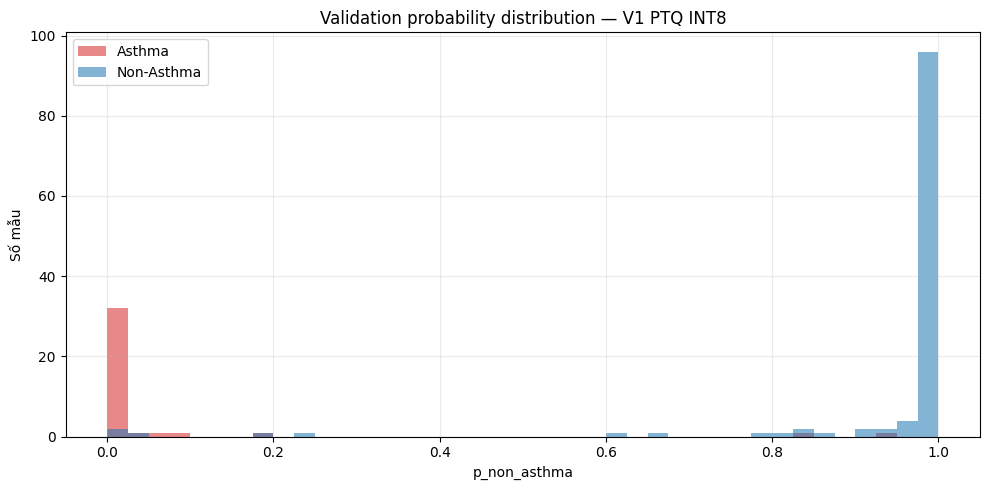

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
for label, color in [(0, 'tab:red'), (1, 'tab:blue')]:
    values = val_df.loc[val_df['true_label'] == label, 'p_non_asthma']
    name = 'Asthma' if label == 0 else 'Non-Asthma'
    ax.hist(values, bins=np.linspace(0, 1, 41), alpha=0.55, label=name, color=color)
ax.set(xlabel='p_non_asthma', ylabel='Số mẫu', title='Validation probability distribution — V1 PTQ INT8')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'validation_probability_distribution.png', dpi=160)
plt.show()


## 3. Candidate Threshold Comparison

**Mục đích:** so sánh nhanh các cặp LOW/HIGH được đề xuất trước khi quét lưới rộng.

Mỗi cặp được đánh giá bằng Asthma miss, Asthma/Non-Asthma Unsure, false alarm, Recall, F1, coverage và accepted accuracy. Kết quả ở bước này chỉ để so sánh, chưa phải cấu hình cuối.

**Artifact:** `results/candidate_threshold_comparison.csv`.

In [9]:
CANDIDATES = [
    (0.40, 0.60), 
    (0.45, 0.65), 
    (0.45, 0.70), 
    (0.50, 0.65)
]

candidate_df = compare_candidates(val_df, CANDIDATES)
candidate_df.to_csv(RESULTS_DIR / 'candidate_threshold_comparison.csv', index=False, encoding='utf-8-sig')

display(candidate_df)


,low_threshold,high_threshold,total,asthma_total,non_asthma_total,asthma_to_asthma,asthma_to_unsure,asthma_to_non_asthma,non_asthma_to_asthma,non_asthma_to_unsure,...,asthma_f1,asthma_miss_rate,asthma_unsure_rate,non_asthma_false_alarm_rate,non_asthma_unsure_rate,overall_unsure_rate,coverage,accepted_accuracy,strict_accuracy,decision_pattern_sha256
0,0.40,0.60,154,38,116,36,0,2,5,0,...,0.911392,0.052632,0.0,0.043103,0.000000,0.000000,1.000000,0.954545,0.954545,9fd5b9d3d1813d101091e33f7bab42a25c8451ab751c88...
1,0.45,0.65,154,38,116,36,0,2,5,1,...,0.911392,0.052632,0.0,0.043103,0.008621,0.006494,0.993506,0.954248,0.948052,0c09732aad0d6a4c35a9c3c9bfe3cfefbc482d013f2f5e...
2,0.45,0.70,154,38,116,36,0,2,5,2,...,0.911392,0.052632,0.0,0.043103,0.017241,0.012987,0.987013,0.953947,0.941558,915f3bfc61a6cec79f2187d2c74ba101417201855ac390...
3,0.50,0.65,154,38,116,36,0,2,5,1,...,0.911392,0.052632,0.0,0.043103,0.008621,0.006494,0.993506,0.954248,0.948052,0c09732aad0d6a4c35a9c3c9bfe3cfefbc482d013f2f5e...


## 4. Threshold Grid Sweep

**Mục đích:** quét nhiều cặp LOW/HIGH trên toàn bộ Validation và xếp hạng theo rủi ro lâm sàng/post-processing. Có thể đặt constraint để loại các cặp có miss, Unsure hoặc false alarm vượt giới hạn.

Grid sweep không dùng Test. Vì output INT8 là rời rạc, nhiều cặp threshold có thể tạo cùng quyết định; chúng được đánh dấu bằng `duplicate_decision_pattern`.

**Đầu ra hiển thị:** `ranked_df`. **Artifact:** `results/threshold_grid_sweep.csv`.

In [10]:
sweep_df = threshold_grid_sweep(val_df)
sweep_df.to_csv(RESULTS_DIR / 'threshold_grid_sweep.csv', index=False, encoding='utf-8-sig')

# Chỉnh constraint sau khi xem phân bố và candidate cơ bản.
MAX_ASTHMA_MISS_RATE = None
MAX_OVERALL_UNSURE_RATE = None
MAX_NON_ASTHMA_FALSE_ALARM_RATE = None

ranked_df = rank_candidates(
    sweep_df,
    max_asthma_miss_rate=MAX_ASTHMA_MISS_RATE,
    max_overall_unsure_rate=MAX_OVERALL_UNSURE_RATE,
    max_non_asthma_false_alarm_rate=MAX_NON_ASTHMA_FALSE_ALARM_RATE,
)
display(ranked_df.head(30))


,low_threshold,high_threshold,total,asthma_total,non_asthma_total,asthma_to_asthma,asthma_to_unsure,asthma_to_non_asthma,non_asthma_to_asthma,non_asthma_to_unsure,...,asthma_miss_rate,asthma_unsure_rate,non_asthma_false_alarm_rate,non_asthma_unsure_rate,overall_unsure_rate,coverage,accepted_accuracy,strict_accuracy,decision_pattern_sha256,duplicate_decision_pattern
0,0.25,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,False
1,0.26,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True
2,0.27,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True
3,0.28,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True
4,0.29,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True
5,0.30,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True
6,0.31,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True
7,0.32,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True
8,0.33,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True
9,0.34,0.95,154,38,116,36,2,0,5,11,...,0.0,0.052632,0.043103,0.094828,0.084416,0.915584,0.964539,0.883117,15aeb79b94b4986110459d756c9865d8a592d11bd2da49...,True


## 5. Final Threshold Selection

**Mục đích:** nhập thủ công đúng một cặp LOW/HIGH sau khi đã xem distribution, candidate và grid sweep. Notebook không tự động lấy hàng đầu tiên.

Cell tính lại metric của cặp vừa chọn và hiển thị riêng các sample `WRONG`/`UNSURE` để kiểm tra nguồn lỗi. Ở bước này cấu hình vẫn chưa được freeze và chưa mở Test.

In [ ]:
FINAL_LOW = None   # Ví dụ: 0.45
FINAL_HIGH = None  # Ví dụ: 0.65
SELECTION_NOTE = ''

if FINAL_LOW is None or FINAL_HIGH is None:
    raise ValueError('Phải nhập FINAL_LOW và FINAL_HIGH sau khi đánh giá Validation')
if not SELECTION_NOTE.strip():
    raise ValueError('Phải ghi lý do chọn threshold trong SELECTION_NOTE')

final_val_metrics = compute_metrics(
    val_df['true_label'].to_numpy(),
    val_df['p_non_asthma'].to_numpy(),
    FINAL_LOW, FINAL_HIGH,
)
display(pd.DataFrame([final_val_metrics]))

val_annotated = annotate_predictions(val_df, FINAL_LOW, FINAL_HIGH)
display(val_annotated[val_annotated['final_correct'] != 'CORRECT'])


## 6. Export FINAL Config

**Mục đích:** đóng băng cặp threshold đã chọn hoàn toàn bằng Validation.

**Artifact:** `validation_predictions_final.csv` và `final_threshold.json`. JSON lưu LOW/HIGH, model SHA-256, output scale/zero-point, metric Validation và lý do lựa chọn.

> Sau khi chạy cell này, LOW/HIGH được coi là `FROZEN`; không đổi lại dựa trên kết quả Test.

In [ ]:
val_annotated.to_csv(RESULTS_DIR / 'validation_predictions_final.csv', index=False, encoding='utf-8-sig')
config_path = export_final_config(
    FINAL_CONFIG,
    FINAL_LOW, FINAL_HIGH,
    final_val_metrics,
    val_metadata,
    SELECTION_NOTE,
)
print(config_path.read_text(encoding='utf-8'))


## 7. Final Test Evaluation

**Mục đích:** xác nhận duy nhất cặp LOW/HIGH đã freeze trên 159 mẫu Test độc lập. Cell tự sinh Test predictions nếu chưa có, sau đó áp dụng config mà không sweep lại.

**Artifact:** `test_predictions.csv`, `final_test_result.csv`, `final_test_metrics.csv` và `final_test_metrics.json`.

> Chỉ chạy sau khi `final_threshold.json` có `status=FROZEN`. Không dùng Test để quay lại đổi LOW/HIGH.

In [ ]:
final_config = load_final_config(FINAL_CONFIG)
if not TEST_CSV.is_file():
    generate_predictions('test', TEST_CSV, FINAL_CONFIG)

test_df = load_predictions(TEST_CSV)
test_metrics = compute_metrics(
    test_df['true_label'].to_numpy(),
    test_df['p_non_asthma'].to_numpy(),
    final_config['low_threshold'],
    final_config['high_threshold'],
)
test_annotated = annotate_predictions(
    test_df, final_config['low_threshold'], final_config['high_threshold']
)
test_annotated.to_csv(RESULTS_DIR / 'final_test_result.csv', index=False, encoding='utf-8-sig')
write_metrics_csv(RESULTS_DIR / 'final_test_metrics.csv', test_metrics)
(RESULTS_DIR / 'final_test_metrics.json').write_text(
    json.dumps(test_metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8'
)
display(pd.DataFrame([test_metrics]))


## 8. Conclusion

Tóm tắt quyết định cuối của bước Classification Threshold và bằng chứng trên Validation/Test. Phần này cần trả lời rõ cặp ngưỡng có được chấp nhận cho Patient Node FINAL V1 hay không.

Điền kết luận sau khi hoàn thành:

- LOW đã freeze: `...`
- HIGH đã freeze: `...`
- Validation Asthma miss / Unsure / false alarm: `...`
- Test Asthma miss / Unsure / false alarm: `...`
- Cặp ngưỡng có được chấp nhận cho Patient Node FINAL V1 không: `...`
- Giới hạn đã biết: `...`

> Không chỉnh lại threshold sau khi đã xem Test. Nếu không đạt, ghi nhận thí nghiệm thất bại và thiết kế protocol mới với một tập đánh giá độc lập khác.